In [23]:
import pandas as pd
import os
import pickle

import sys
sys.path.insert(0, "../../..")

from utils.data_processing import add_boundary_column

In [24]:
df = pd.read_csv("../dataset_construction/datasets/processed_aeema.csv")
df["subject"] = df["art_f"].apply(lambda x: os.path.basename(x).split("_")[2])
df = add_boundary_column(df, lang="ae")

In [25]:
distance_df = pd.read_csv("../distinctiveness_calculation/distances_aeema.csv")
surprisal_df = pd.read_csv("../surprisal_calculation/surprisal_aeema.csv")

In [26]:
for col_name in distance_df.columns:
    df[col_name] = distance_df[col_name]
    
for col_name in surprisal_df.columns:
    df[col_name] = surprisal_df[col_name]

In [27]:
with open("../../flexibility_estimation/entropy_estimation/entropies/aeema_art_given_ac.pickle", "rb") as f:
    H_art_given_ac_mdn = pickle.load(f)
with open("../../flexibility_estimation/entropy_estimation/entropies/aeema_ac_given_art.pickle", "rb") as f:
    H_ac_given_art_mdn = pickle.load(f)

In [28]:
flexibility_df = pd.read_csv("../../flexibility_estimation/mutual_information_estimation/res/aeema.csv")
flexibility_df.sort_values(by="flexibility", inplace=True)

In [29]:
phone2flexibility = dict(zip(flexibility_df["phone"], flexibility_df["flexibility"]))
H_art_given_ac_mdn = dict(zip(flexibility_df["phone"], flexibility_df["H_art_given_ac_phone"]))

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='phone', ylabel='H_art_given_ac_phone'>

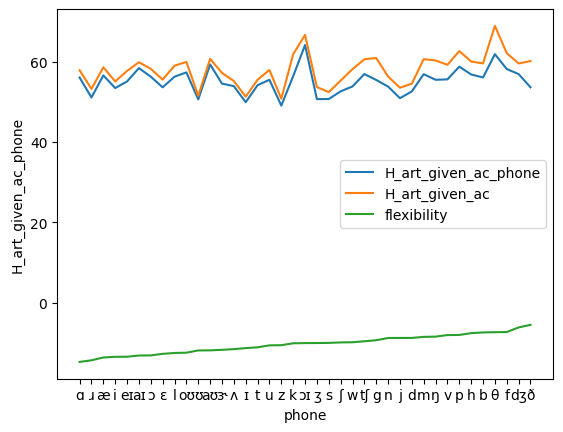

In [31]:
H_art_given_ac_mdn = dict(sorted(H_art_given_ac_mdn.items(), key=lambda item: item[1]))
sns.lineplot(data=flexibility_df, x="phone", y="H_art_given_ac_phone", label="H_art_given_ac_phone")
sns.lineplot(data=flexibility_df, x="phone", y="H_art_given_ac", label="H_art_given_ac")
sns.lineplot(data=flexibility_df, x="phone", y="flexibility", label="flexibility")

In [32]:
df["phone1_H_art_given_ac"] = df.apply(lambda x: H_art_given_ac_mdn[x["phone1"]], axis=1)
df["phone2_H_art_given_ac"] = df.apply(lambda x: H_art_given_ac_mdn[x["phone2"]], axis=1)
df["phone1_flexibility"] = df.apply(lambda x: phone2flexibility[x["phone1"]], axis=1)
df["phone2_flexibility"] = df.apply(lambda x: phone2flexibility[x["phone2"]], axis=1)

In [33]:
df

,phone1_start,phone1_end,phone2_start,phone2_end,phone1,phone2,context,word,word_id,art_f,...,art_latent_dist,ac_latent_dist,bigram_surprisal,phone2_pos_entropy,phone1_freq,phone2_freq,phone1_H_art_given_ac,phone2_H_art_given_ac,phone1_flexibility,phone2_flexibility
0,1.203764,1.273764,1.273764,1.353764,m,æ,m,masquerade,usctimit_ema_m1_081_085.mat_0.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/M1/mat/u...,...,6.749575,18.722214,6.009368,2.414720,596363,771817,56.865299,56.557534,-8.469125,-13.594866
1,1.273764,1.353764,1.353764,1.443764,æ,s,m_æ,masquerade,usctimit_ema_m1_081_085.mat_0.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/M1/mat/u...,...,7.431067,15.735161,NaN,1.905502,771817,1068478,56.557534,50.695013,-13.594866,-9.964216
2,1.353764,1.443764,1.443764,1.513764,s,k,m_æ_s,masquerade,usctimit_ema_m1_081_085.mat_0.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/M1/mat/u...,...,9.173602,12.153953,4.393861,1.262031,1068478,725120,50.695013,56.361758,-9.964216,-10.064453
3,1.443764,1.513764,1.513764,1.653764,k,ɝ,m_æ_s_k,masquerade,usctimit_ema_m1_081_085.mat_0.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/M1/mat/u...,...,8.863888,17.519503,4.869072,1.349007,725120,478205,56.361758,54.522613,-10.064453,-11.687665
4,1.513764,1.653764,1.653764,1.763764,ɝ,eɪ,m_æ_s_k_ɝ,masquerade,usctimit_ema_m1_081_085.mat_0.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/M1/mat/u...,...,11.051079,16.721310,NaN,0.000000,478205,516769,54.522613,55.056299,-11.687665,-13.409059
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43454,23.919070,23.999070,23.999070,24.089070,ʃ,ʌ,k_ɑ_m_p_ʌ_t_ɪ_ʃ,competition,usctimit_ema_f1_121_125.mat_35.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/F1/mat/u...,...,5.398518,17.511381,-0.000000,0.000000,153715,1986727,52.593759,53.891001,-9.851559,-11.515573
43455,23.999070,24.089070,24.089070,24.149070,ʌ,n,k_ɑ_m_p_ʌ_t_ɪ_ʃ_ʌ,competition,usctimit_ema_f1_121_125.mat_35.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/F1/mat/u...,...,4.609133,17.073650,-0.000000,0.000000,1986727,1565283,53.891001,53.776644,-11.515573,-8.743306
43456,24.149070,24.179070,24.179070,24.209070,h,w,h,which,usctimit_ema_f1_121_125.mat_36.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/F1/mat/u...,...,2.221121,10.556767,4.097321,2.148458,383368,457449,56.791682,53.820538,-7.541714,-9.801236
43457,24.179070,24.209070,24.209070,24.239070,w,ɪ,h_w,which,usctimit_ema_f1_121_125.mat_36.0,/Volumes/Transcend/USC-TIMIT/EMA/Data/F1/mat/u...,...,2.079784,9.867956,3.520823,1.239639,457449,1299207,53.820538,49.898171,-9.801236,-11.264912


In [34]:
is_limited = [
    'h',    # Glottal (no sensor)
    'm', 'n', 'ŋ',  # Nasals (no velum sensor)
    'ɹ', 'ɝ', 'ɚ', # Rhotics (no pharyngeal sensor)
    'aɪ', 'aʊ', 'æ', 'ɑ', 
]
df["is_limited"] = [1 if phone1 in is_limited or phone2 in is_limited else 0 for phone1, phone2 in zip(df["phone1"], df["phone2"])]

In [35]:
df["token_id"] = df.index

In [36]:
# df.to_csv("results_aeema_wide.csv", index=False)

In [37]:
dist_cols = [
    "ac_latent_dist",
    # "ac_raw_dist",
    "art_latent_dist",
    # "art_raw_dist"
]

df_long = df.melt(
    id_vars=[col for col in df.columns if col not in dist_cols],
    value_vars=dist_cols,
    var_name="dist_type",
    value_name="dist"
)

df_long[["modality", "data_space"]] = (
    df_long["dist_type"]
    .str.extract(r"^(ac|art)_(latent|raw)_dist$")
)

df_long = df_long.drop(columns="dist_type")
df_long.to_csv("results_aeema.csv", index=False)